# **PART 1 (Prof. Galfrè)**

##### **1. Differential Expression Analysis**

The same datasets reported in the paper were used. The GEO accession numbers are:
- GSE113513, including 14 non-tumoral colorectal tissue samples and 14 colorectal cancer (CRC) tissue samples;
- GSE134834, including 5 CRC tissue samples and 5 adjacent normal tissue samples;
- GSE110223, including 13 primary colorectal adenocarcinoma samples and 13 adjacent normal tissue samples;
- GSE22598, including 17 homogenized tumor tissue samples and 17 homogenized normal tissue samples. In this dataset,
4 colorectal cancer cell lines were present but were not considered in the analysis, since they were also excluded in the paper.

Differentially expressed genes (DEGs) were identified using GEO2R, which allows the comparison between normal and tumor tissue samples. Samples were divided into two groups: `tumor` and `non-tumor`.

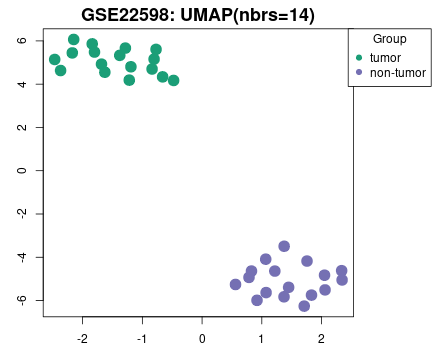

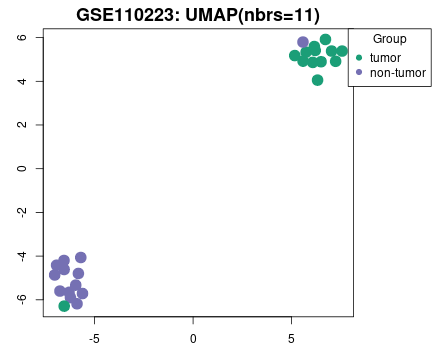

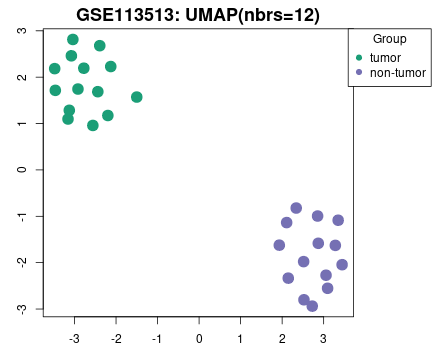

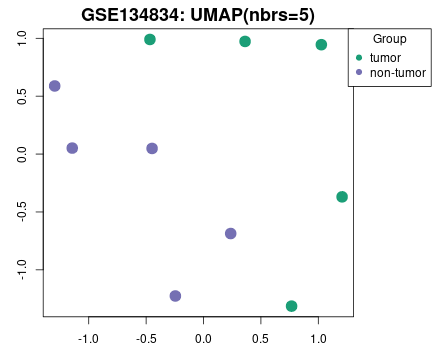

In [113]:
from IPython.display import Image, display

display(Image(filename="IMG/GSE22598.jpg", width=200))
display(Image(filename="IMG/GSE110223.jpg", width=200))
display(Image(filename="IMG/GSE113513.jpg", width=200))
display(Image(filename="IMG/GSE134834.jpg", width=200))


UMAP plots generally show a good separation between tumor and non-tumor samples.

However:
- in the GSE134834 UMAP, the separation is slightly less clear, but still acceptable;

- in the GSE110223 UMAP, two samples appear farther from their expected cluster, likely due to variability or noise in
 the data.

Expression data normalization was automatically handled by GEO2R, which applies quantile normalization.

P-values were corrected using the Benjamini–Hochberg method to control the False Discovery Rate (FDR).

Statistically significant genes were selected using the same thresholds adopted in the paper:
- adjusted p-value < 0.05
- logFC ≥ 2 or ≤ −2

Genes with logFC ≥ 2 were classified as upregulated (higher expression in tumor samples), while genes with logFC ≤ −2 were classified as downregulated (lower expression in tumor samples).

After obtaining the lists of DEGs for each GEO dataset using GEO2R, it was checked that the four .csv files contain the three required columns `Gene.Symbol`, `adj.P.Val`, and `logFC`, and that `adj.P.Val` and `logFC` are numeric values and not strings.

In [114]:
import pandas as pd

files = [
    "GSE113513.top.table.tsv",
    "GSE134834.top.table.tsv",
    "GSE110223.top.table.tsv",
    "GSE22598.top.table.tsv"
]

for file in files:
    print("\n----------------------------------------")
    print(f"FILE: {file}")
    df = pd.read_csv("GSE_table/" + file, sep="\t")
    print(df.columns)
    print("\nShape (righe, colonne):", df.shape)
    display(df.head(2))
    df.info()



----------------------------------------
FILE: GSE113513.top.table.tsv
Index(['ID', 'adj.P.Val', 'logFC', 'Gene.Symbol'], dtype='object')

Shape (righe, colonne): (49395, 4)


,ID,adj.P.Val,logFC,Gene.Symbol
0,11739128_a_at,1.500000e-12,3.46,CDH3
1,11719434_a_at,2.870000e-12,2.34,ETV4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49395 entries, 0 to 49394
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           49395 non-null  object 
 1   adj.P.Val    49395 non-null  float64
 2   logFC        49395 non-null  float64
 3   Gene.Symbol  49372 non-null  object 
dtypes: float64(2), object(2)
memory usage: 1.5+ MB

----------------------------------------
FILE: GSE134834.top.table.tsv
Index(['ID', 'adj.P.Val', 'logFC', 'Gene.Symbol'], dtype='object')

Shape (righe, colonne): (33684, 4)


,ID,adj.P.Val,logFC,Gene.Symbol
0,A_23_P52761,0.000066,6.926572,MMP7
1,A_23_P39067,0.000066,-3.745836,SPIB


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33684 entries, 0 to 33683
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           33684 non-null  object 
 1   adj.P.Val    33684 non-null  float64
 2   logFC        33684 non-null  float64
 3   Gene.Symbol  19329 non-null  object 
dtypes: float64(2), object(2)
memory usage: 1.0+ MB

----------------------------------------
FILE: GSE110223.top.table.tsv
Index(['ID', 'adj.P.Val', 'logFC', 'Gene.Symbol'], dtype='object')

Shape (righe, colonne): (22283, 4)


,ID,adj.P.Val,logFC,Gene.Symbol
0,203498_at,0.000094,-1.146283,RCAN2
1,209687_at,0.000094,-2.662972,CXCL12


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22283 entries, 0 to 22282
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           22283 non-null  object 
 1   adj.P.Val    22283 non-null  float64
 2   logFC        22283 non-null  float64
 3   Gene.Symbol  21156 non-null  object 
dtypes: float64(2), object(2)
memory usage: 696.5+ KB

----------------------------------------
FILE: GSE22598.top.table.tsv
Index(['ID', 'adj.P.Val', 'logFC', 'Gene.Symbol'], dtype='object')

Shape (righe, colonne): (54675, 4)


,ID,adj.P.Val,logFC,Gene.Symbol
0,222549_at,8.770000e-15,4.46,CLDN1
1,201340_s_at,3.080000e-14,3.33,ENC1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54675 entries, 0 to 54674
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           54675 non-null  object 
 1   adj.P.Val    54675 non-null  float64
 2   logFC        54675 non-null  float64
 3   Gene.Symbol  45118 non-null  object 
dtypes: float64(2), object(2)
memory usage: 1.7+ MB


Creation of volcano plots to compare them with those reported in the paper.

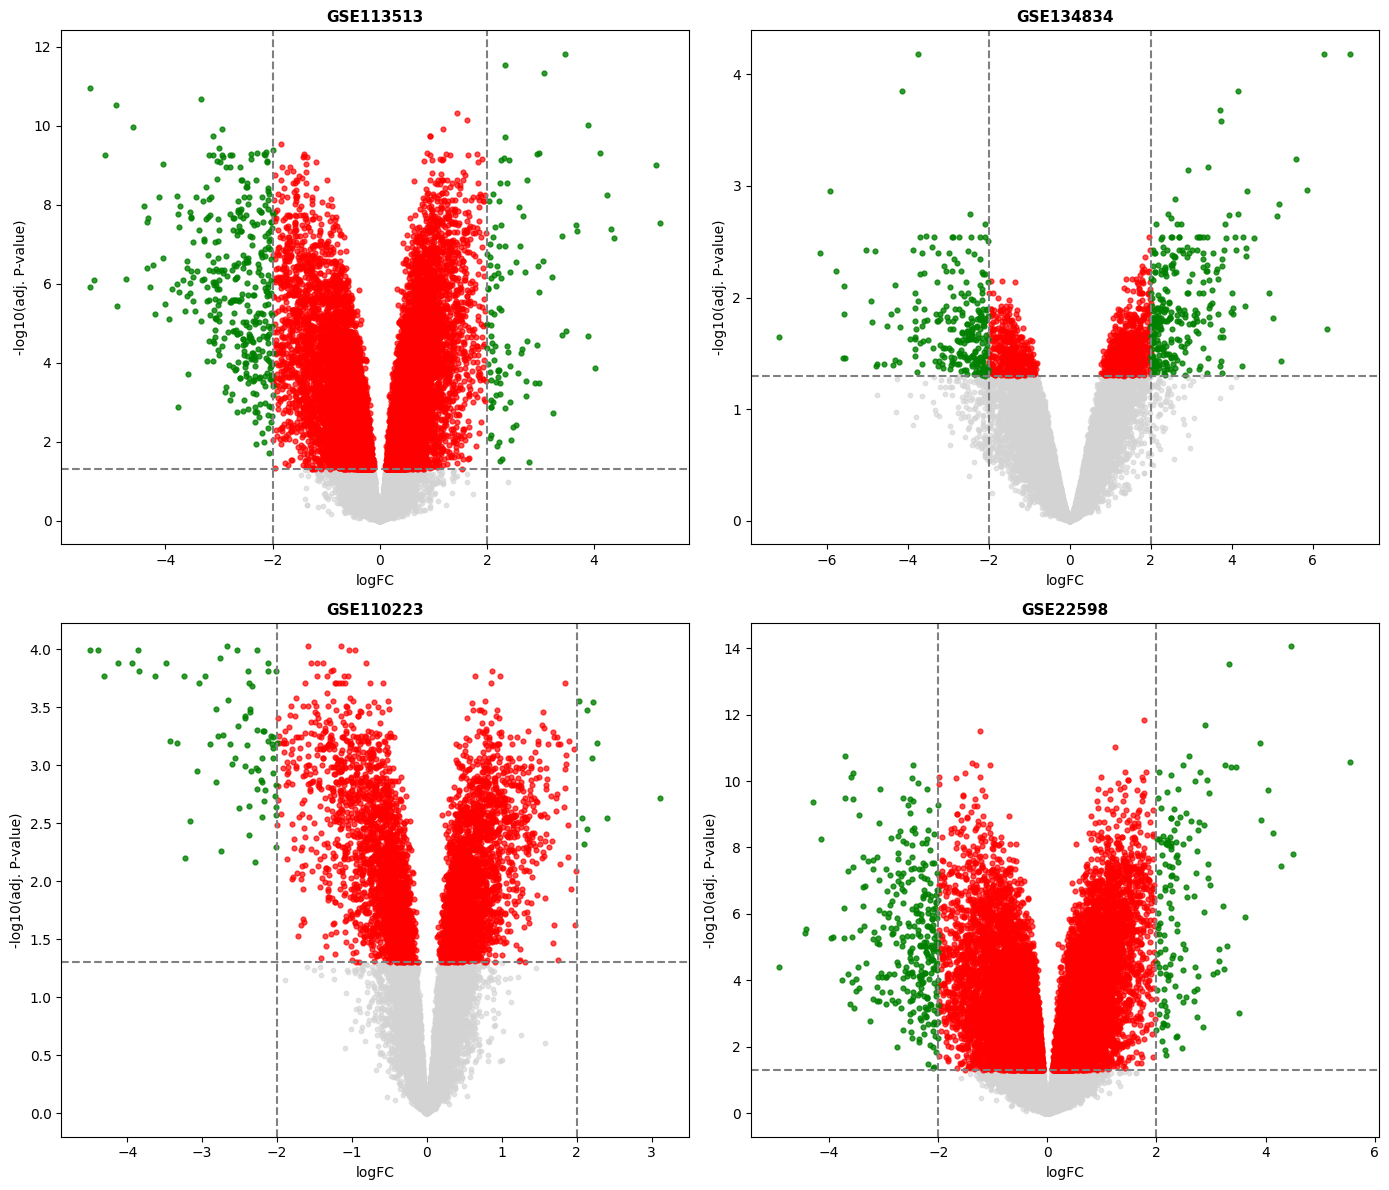

In [115]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

files = [
    "GSE113513.top.table.tsv",
    "GSE134834.top.table.tsv",
    "GSE110223.top.table.tsv",
    "GSE22598.top.table.tsv"
]
titles = [
    "GSE113513",
    "GSE134834",
    "GSE110223",
    "GSE22598"
]
p_cut = 0.05
logfc_cut = 2
y_cut = -np.log10(p_cut)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, file, title in zip(axes, files, titles):
    df = pd.read_csv("GSE_table/" + file, sep="\t")
    df = df.dropna(subset=["adj.P.Val", "logFC"])

    # categorie
    background = df["adj.P.Val"] >= p_cut
    red = (df["adj.P.Val"] < p_cut) & (df["logFC"].abs() < logfc_cut)
    green = (df["adj.P.Val"] < p_cut) & (df["logFC"].abs() >= logfc_cut)

    # background
    ax.scatter(
        df.loc[background, "logFC"],
        -np.log10(df.loc[background, "adj.P.Val"]),
        c="lightgrey", s=10, alpha=0.6
    )

    # significativi ma FC basso (rosso)
    ax.scatter(
        df.loc[red, "logFC"],
        -np.log10(df.loc[red, "adj.P.Val"]),
        c="red", s=12, alpha=0.7
    )

    # DEG forti (verde)
    ax.scatter(
        df.loc[green, "logFC"],
        -np.log10(df.loc[green, "adj.P.Val"]),
        c="green", s=12, alpha=0.8
    )

    # cutoff lines
    ax.axhline(y_cut, linestyle="--", color="grey")
    ax.axvline(logfc_cut, linestyle="--", color="grey")
    ax.axvline(-logfc_cut, linestyle="--", color="grey")

    # etichette
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("logFC")
    ax.set_ylabel("-log10(adj. P-value)")

plt.tight_layout()
plt.show()


The gene distribution shows a similar overall shape across all datasets when comparing the performed analysis with the one reported in the paper. However, the distribution of significant genes differs slightly in some cases, more markedly in certain datasets.

In particular, in GSE110223 and GSE113513 a higher prevalence of downregulated genes emerges in the performed analysis, whereas the paper reports a higher number of upregulated genes.

This difference shows that, even if the overall distribution looks similar, the proportion of up- and down-regulated genes changes between the two analyses. For this reason, the volcano plots give a first impression that the analysis may produce slightly different results than those in the paper.

Below are the DEGs shared by all four datasets, with each gene counted only once.

In [116]:
import pandas as pd
from functools import reduce

deg_sets = {}

for gse in files:
    df = pd.read_csv("GSE_table/" + gse, sep="\t")
    # split simboli multipli tipo "GABBR1 /// UBD"
    df["Gene.Symbol"] = df["Gene.Symbol"].str.split(" /// ")
    df = df.explode("Gene.Symbol")
    df["Gene.Symbol"] = df["Gene.Symbol"].str.strip()
    deg_df = df[(df["adj.P.Val"] < 0.05)] # applicazione soglie

    # lista dei geni (value) del gse (chiave)
    deg_sets[gse] = set(deg_df["Gene.Symbol"])
    print(f"{gse}: {len(deg_sets[gse])} DEG unici")

print("")
# intersezione: geni comuni a tutti i gse
common_genes = reduce(set.intersection, deg_sets.values())
for gene in sorted(common_genes):
    print(gene)

print(f"\nTotale geni comuni: {len(common_genes)}")


GSE113513.top.table.tsv: 9033 DEG unici
GSE134834.top.table.tsv: 1051 DEG unici
GSE110223.top.table.tsv: 3672 DEG unici
GSE22598.top.table.tsv: 10508 DEG unici

ABCA8
ABCC1
ACACA
ACADS
ACVR2A
ADAM28
ADAMDEC1
ADH1A
ADRM1
AFF1
AGFG2
AGT
AHCY
AHCYL2
ALDH1B1
ALDH4A1
AMPD1
ANGPT2
APPL2
APTX
AQP8
ARHGAP44
ARNTL2
ASB9
ASCL2
ASNS
ASPHD1
ATAD2
ATP11A
ATP2A3
AURKA
BDH1
BEST2
BIRC5
BLM
BORA
BRCA1
BRCA2
BRIX1
BTNL3
BTNL8
BUB1
BUB3
C14orf159
C2
C7
CA1
CA2
CA4
CA7
CACYBP
CALU
CAV1
CBX3
CBX4
CCDC85B
CCNB1
CCNF
CCT4
CCT7
CD177
CD209
CDC25A
CDC25B
CDCA3
CDH19
CDH3
CDHR5
CDK2
CDK5
CDKN3
CDT1
CEBPB
CENPF
CENPI
CENPN
CENPQ
CEP55
CES3
CFB
CFD
CFI
CGREF1
CHAD
CHAF1B
CHEK2
CHGA
CHL1
CHP2
CHST5
CKAP2
CKB
CKS1B
CKS2
CLCA1
CLDN1
CLDN8
CLMN
CNNM2
COL1A1
COL1A2
COL4A1
COL5A2
COX7A1
CSE1L
CST1
CWH43
CXCL1
CXCL12
CXCL2
CXCL3
DACH1
DARS
DBF4
DBNDD1
DCLK1
DHRS11
DPEP1
DPY19L1
DSN1
DUSP14
E2F6
EDN3
EDNRA
EEF1E1
EGFL6
EIF1AX
EIF2S2
EIF3B
ELOVL5
ENC1
ENTPD5
EPHX2
ETV4
EXO1
EXOSC4
EXOSC5
FABP6
FAM46C
FANCG
FANCI
FAP
FARP

Below are all genes that are significant in at least one of the four datasets.

In [117]:
all_deg = reduce(set.union, deg_sets.values())
print(f"Totale DEG: {len(all_deg)}")

Totale DEG: 14077


In [118]:
common_up = {}
common_down = {}

for gse in files:
    df = pd.read_csv("GSE_table/" + gse, sep="\t")
    df["Gene.Symbol"] = df["Gene.Symbol"].str.split(" /// ")
    df = df.explode("Gene.Symbol")
    df["Gene.Symbol"] = df["Gene.Symbol"].str.strip()
    df_common = df[df["Gene.Symbol"].isin(common_genes)]
    common_up[gse] = set(df_common[df_common["logFC"] >= 2]["Gene.Symbol"])
    common_down[gse] = set(df_common[df_common["logFC"] <= -2]["Gene.Symbol"])

overexpressed = reduce(set.intersection, common_up.values())
underexpressed = reduce(set.intersection, common_down.values())


In [119]:
# geni sottoespressi
for g in sorted(underexpressed):
    print(g)

print("\nTotale geni sottoespressi:", len(underexpressed))

ABCA8
ADAMDEC1
AQP8
CA1
CA2
CA4
CD177
CHP2
CLCA1
CLDN8
CXCL12
GCG
GUCA2A
GUCA2B
HPGD
LGALS2
MS4A12
MT1F
MT1H
MT1M
NR3C2
PADI2
PCK1
SLC4A4

Totale geni sottoespressi: 24


In [120]:
# geni sovraespressi
for g in sorted(overexpressed):
    print(g)

print("\nTotale geni sovraespressi:", len(overexpressed))


CDH3
CXCL1
MMP1
MMP3
TGFBI

Totale geni sovraespressi: 5


Compared to the paper, a different number of differentially expressed genes was identified.

In particular, the analysis identified a higher total number of DEGs (14,077 instead of 98) and, consequently, a
different number of common genes (447 instead of 39) and downregulated genes (24 instead of 34).

On the other hand, the upregulated genes identified are 5, corresponding to the hub genes reported in the paper.

These differences can be attributed to methodological choices adopted in the analysis, such as the use of the GEO2R web tool instead of the limma package in R, as well as possible differences in data preprocessing.

#### **2. Functional Enrichment Analysis**
The functional enrichment analysis was performed using g:Profiler.

The ORA approach was chosen because it is consistent with the one used in the reference paper and therefore makes the comparison easier.

So, the results obtained from the previous analysis were used as input:

- a list of 24 downregulated genes
- a background of 27206 unique genes, including all genes from the four GEO datasets, without applying thresholds on
p-value or logFC. In this way, the analysis is based only on genes observed in the experiments and not on the default background provided by g:Profiler.

The analysis was then repeated using the five upregulated genes.

To identify significantly enriched terms, a statistical significance threshold based on adjusted p-value (FDR) was applied, set to 0.05.

The code and observations related to the analysis are reported below:

Creation of the background for ORA analysis using g:Profiler

In [121]:
import pandas as pd
from functools import reduce

background_sets = []

for file in files:
    df = pd.read_csv("GSE_table/" + file, sep="\t")
    genes = (df["Gene.Symbol"].dropna().str.split(" /// ").explode().str.strip())
    background_sets.append(set(genes))
    print(f"{file}: {len(set(genes))} geni misurati")

background_genes = sorted(reduce(set.union, background_sets))
print(f"Totale geni nel background: {len(background_genes)}")

with open("background_genes_gprofiler.txt", "w") as f:
    for gene in background_genes:
        f.write(gene + "\n")


GSE113513.top.table.tsv: 20623 geni misurati
GSE134834.top.table.tsv: 14508 geni misurati
GSE110223.top.table.tsv: 13299 geni misurati
GSE22598.top.table.tsv: 22189 geni misurati
Totale geni nel background: 27206


Extraction of KEGG pathways and GO terms (MF and BP) associated with downregulated and upregulated genes, as reported
 in the
reference paper (Figure 7).

In [122]:
kegg_downregulated_paper = [
    "Metabolic pathways",
    "Pancreatic secretion",
    "Proximal tubule bicarbonate reclamation",
    "Nitrogen metabolism",
    "Bile secretion",
    "Mineral absorption"
]
mf_downregulated_paper = [
    "zinc ion binding",
    "oxidoreductase activity",
    "hydro-lyase activity",
    "carbonate dehydratase activity",
    "metalloendopeptidase activity",
    "retinol dehydrogenase activity",
    "intracellular calcium-activated chloride channel activity",
    "steroid dehydrogenase activity",
    "alcohol dehydrogenase (NAD) activity",
    "testosterone dehydrogenase (NAD+) activity",
    "arylesterase activity",
    "guanylate cyclase activator activity",
    "cyanamide hydratase activity"
]
bp_downregulated_paper = [
    "proteolysis",
    "one-carbon metabolic process",
    "cellular response to cadmium ion",
    "cellular zinc ion homeostasis",
    "cellular response to copper ion",
    "cellular response to zinc ion",
    "negative regulation of growth",
    "detoxification of copper ion",
    "regulation of intracellular pH",
    "bicarbonate transport",
    "androgen metabolic process",
    "positive regulation of calcium ion import",
    "positive regulation of guanylate cyclase activity"
]
# --------------------------------------
kegg_upregulated_paper = [
    "Lipid and atherosclerosis",
    "IL-17 signaling pathway",
    "Rheumatoid arthritis",
    "Coronavirus disease - COVID-19",
    "TNF signaling pathway"
]
mf_bp_upregulated_paper = [
    "serine-type endopeptidase activity",
    "metalloendopeptidase activity",
    "peptidase activity",
    "endopeptidase activity",
    "extracellular matrix organization",
    "proteolysis",
    "visual perception",
    "positive regulation of protein complex assembly",
    "extracellular matrix disassembly",
    "collagen catabolic process",
    "cellular response to UV-A"
]


Below, a function is defined to extract GO terms (BP and MF) and KEGG pathways from g:Profiler CSV files for both upregulated and downregulated genes.

In [123]:
def from_df_to_term_name_list(csv_path):
    df = pd.read_csv(csv_path)
    bp_terms = df[df["source"] == "GO:BP"]["term_name"].tolist()
    mf_terms = df[df["source"] == "GO:MF"]["term_name"].tolist()
    kegg_terms = df[df["source"] == "KEGG"]["term_name"].tolist()
    return bp_terms, mf_terms, kegg_terms


In [124]:
bp_down, mf_down, kegg_down = from_df_to_term_name_list("enrichment/DOWN_gProfiler_hsapiens_intersections.csv")
bp_up, mf_up, kegg_up = from_df_to_term_name_list("enrichment/UP_gProfiler_hsapiens_intersections.csv")

mf_bp_up = bp_up + mf_up

In [125]:
mf_bp_up

['cellular response to UV-A',
 'response to UV-A',
 'extracellular structure organization',
 'collagen catabolic process',
 'extracellular matrix organization',
 'external encapsulating structure organization',
 'extracellular matrix disassembly',
 'cellular response to UV',
 'positive regulation of melanosome transport',
 'negative regulation of timing of catagen',
 'collagen metabolic process',
 'positive regulation of tyrosinase activity',
 'cellular response to light stimulus',
 'regulation of melanosome transport',
 'negative regulation of hair follicle maturation',
 'response to UV',
 'cellular response to radiation',
 'catagen',
 'regulation of timing of catagen',
 'positive regulation of protein-containing complex assembly',
 'visual perception',
 'cellular response to lipopolysaccharide',
 'cellular response to molecule of bacterial origin',
 'sensory perception of light stimulus',
 'negative regulation of hair follicle development',
 'cellular response to biotic stimulus',
 '

The following function compares the terms reported in the paper with those obtained from the enrichment analysis, checking which ones are present and which ones are not.

In [126]:
def compare_terms_exact(paper_terms, ref_terms):
    match = []
    unmatch = []
    for paper_term in paper_terms:
        if paper_term in ref_terms:
            print(f"{paper_term} is PRESENT")
            match.append(paper_term)
        else:
            unmatch.append(paper_term)
    print("--------------------------")
    print("TOT paper_terms:", len(paper_terms))
    print("TOT ref_terms:", len(ref_terms))
    print("--------------------------")
    print("MATCH:", len(match), match)
    print("--------------------------")
    print("UNMATCH:", len(unmatch), unmatch)
    return match, unmatch

##### **DOWNregulated comparison**

In [127]:
bp_down_matches = compare_terms_exact(bp_downregulated_paper, bp_down)

one-carbon metabolic process is PRESENT
cellular response to cadmium ion is PRESENT
cellular response to copper ion is PRESENT
cellular response to zinc ion is PRESENT
detoxification of copper ion is PRESENT
bicarbonate transport is PRESENT
positive regulation of calcium ion import is PRESENT
--------------------------
TOT paper_terms: 13
TOT ref_terms: 37
--------------------------
MATCH: 7 ['one-carbon metabolic process', 'cellular response to cadmium ion', 'cellular response to copper ion', 'cellular response to zinc ion', 'detoxification of copper ion', 'bicarbonate transport', 'positive regulation of calcium ion import']
--------------------------
UNMATCH: 6 ['proteolysis', 'cellular zinc ion homeostasis', 'negative regulation of growth', 'regulation of intracellular pH', 'androgen metabolic process', 'positive regulation of guanylate cyclase activity']


In [128]:
mf_down_matches = compare_terms_exact(mf_downregulated_paper, mf_down)

zinc ion binding is PRESENT
hydro-lyase activity is PRESENT
carbonate dehydratase activity is PRESENT
arylesterase activity is PRESENT
guanylate cyclase activator activity is PRESENT
cyanamide hydratase activity is PRESENT
--------------------------
TOT paper_terms: 13
TOT ref_terms: 30
--------------------------
MATCH: 6 ['zinc ion binding', 'hydro-lyase activity', 'carbonate dehydratase activity', 'arylesterase activity', 'guanylate cyclase activator activity', 'cyanamide hydratase activity']
--------------------------
UNMATCH: 7 ['oxidoreductase activity', 'metalloendopeptidase activity', 'retinol dehydrogenase activity', 'intracellular calcium-activated chloride channel activity', 'steroid dehydrogenase activity', 'alcohol dehydrogenase (NAD) activity', 'testosterone dehydrogenase (NAD+) activity']


In [129]:
kegg_down_matches = compare_terms_exact(kegg_downregulated_paper, kegg_down)

Pancreatic secretion is PRESENT
Proximal tubule bicarbonate reclamation is PRESENT
Nitrogen metabolism is PRESENT
Bile secretion is PRESENT
Mineral absorption is PRESENT
--------------------------
TOT paper_terms: 6
TOT ref_terms: 5
--------------------------
MATCH: 5 ['Pancreatic secretion', 'Proximal tubule bicarbonate reclamation', 'Nitrogen metabolism', 'Bile secretion', 'Mineral absorption']
--------------------------
UNMATCH: 1 ['Metabolic pathways']


For downregulated genes, the comparison shows the following results:
- Biological Process (BP): the paper reports 13 enriched terms, while the present analysis identifies 37, with 7 terms in common.

- Molecular Function (MF): the paper reports 13 terms, the analysis identifies 30, with 6 terms in common.
- KEGG pathways: the paper reports 6 pathways, while the analysis identifies 5, all 5 of which are in common.

##### **UPregulated comparison**

In [130]:
bp_mf_up_matches = compare_terms_exact(mf_bp_upregulated_paper, mf_bp_up)

serine-type endopeptidase activity is PRESENT
metalloendopeptidase activity is PRESENT
extracellular matrix organization is PRESENT
visual perception is PRESENT
extracellular matrix disassembly is PRESENT
collagen catabolic process is PRESENT
cellular response to UV-A is PRESENT
--------------------------
TOT paper_terms: 11
TOT ref_terms: 74
--------------------------
MATCH: 7 ['serine-type endopeptidase activity', 'metalloendopeptidase activity', 'extracellular matrix organization', 'visual perception', 'extracellular matrix disassembly', 'collagen catabolic process', 'cellular response to UV-A']
--------------------------
UNMATCH: 4 ['peptidase activity', 'endopeptidase activity', 'proteolysis', 'positive regulation of protein complex assembly']


In [131]:
kegg_up_matches = compare_terms_exact(kegg_upregulated_paper, kegg_up)

Lipid and atherosclerosis is PRESENT
IL-17 signaling pathway is PRESENT
Rheumatoid arthritis is PRESENT
Coronavirus disease - COVID-19 is PRESENT
TNF signaling pathway is PRESENT
--------------------------
TOT paper_terms: 5
TOT ref_terms: 5
--------------------------
MATCH: 5 ['Lipid and atherosclerosis', 'IL-17 signaling pathway', 'Rheumatoid arthritis', 'Coronavirus disease - COVID-19', 'TNF signaling pathway']
--------------------------
UNMATCH: 0 []


For upregulated genes, the following is observed:
- BP/MF: the paper reports 11 terms, while the analysis identifies 74 terms in total, with 7 terms in common.
- KEGG pathways: both the paper and the analysis report 5 enriched pathways, which completely overlap.

#### **Comparison and Discussion**
The results of the functional enrichment analysis were compared with those reported in the reference paper, considering separately the terms associated with downregulated and upregulated genes, and analyzing Biological Process (BP), Molecular Function (MF), and KEGG pathways.

##### **Similarities and differences**

Although the total number of enriched terms is different, a good overlap can be observed between the results of this analysis and those reported in the paper.

In particular, KEGG pathways are largely the same for both downregulated and upregulated genes, indicating that the main pathways involved in the disease were correctly identified.

Also for Biological Process (BP) and Molecular Function (MF), several terms reported in the paper also appear in the obtained results, suggesting that the analysis is able to identify biological and functional processes.


##### **Possible methodological reasons for the differences**

The differences observed between the results are most likely due to methodological choices.
- For example, the gene list used for the enrichment analysis comes from a DEG analysis performed with tools and procedures different from those used in the paper, which may result in a slightly different selection of up- and downregulated genes.

- In addition, in the ORA approach the results also depend on the chosen gene background, which may not exactly match the one used in the original study.

- Another possible source of difference is the use of g:Profiler as the enrichment tool, which relies on predefined annotations and criteria, while the paper may have used more customized libraries or pipelines.

***
***
# **PART 2 (Prof. Milazzo)**
Two separate analyses were performed for the COAD disease module, using different gene sets, in order to compare their effect on the network results:

- one based only on the five upregulated hub genes reported in the paper;

- another one including both upregulated and downregulated genes obtained from the DEG analysis (in Galfre part).

COAD disease module – hub genes only

In [132]:
coad_module = ["CDH3", "CXCL1", "MMP1", "MMP3", "TGFBI"]
for i in coad_module:
    print(i)

CDH3
CXCL1
MMP1
MMP3
TGFBI


COAD disease module – upregulated + downregulated genes

In [133]:
coad_module_more = list(overexpressed)+list(underexpressed)
for i in coad_module_more:
    print(i)

print("\nTotale geni coad up+down:", len(coad_module_more))

MMP3
MMP1
CXCL1
TGFBI
CDH3
CA4
CA2
MS4A12
MT1H
CLDN8
SLC4A4
CA1
CHP2
CXCL12
MT1M
ABCA8
PCK1
CLCA1
MT1F
ADAMDEC1
AQP8
NR3C2
GUCA2B
GCG
HPGD
CD177
PADI2
GUCA2A
LGALS2

Totale geni coad up+down: 29


The RA disease module was built using RA-associated genes downloaded from the DISGENET database.

In [134]:
df = pd.read_csv("search_result_C0003873.tsv", sep="\t")
ra_module = list(df["gene_symbol"].dropna().astype(str).str.strip())
for g in ra_module:
    print(g)

print("\nTotale geni RA:", len(ra_module))

TNF
PTPN22
HLA-DRB1
IL10
CTLA4
IL1B
CD40
IL2RA
IL2RB
IL6R
IFNG
CRP
NFKBIL1
AGER
IL17A
HLA-DQA1
IL2
IRF5
IL1RN
CIITA
IL6
PTGS2
PADI4
VEGFA
FCGR3A
IL23R
CCR6
HLA-DPB1
TYK2
FCGR2A
STAT4
PTPN2
SLC22A4
CCR1
STAT3
VIM
FAS
TAP2
HLA-DQB1
SPP1
C4B
BGLAP
MPO
SLC11A1
STAT1
FOXP3
PTGS1
CSF2
IL18
IL23A
TNFRSF11B
ANKRD55
CD3E
ADIPOQ
GRK2
CXCR4
MTHFR
IL1A
TNFRSF1A
TNFAIP3
CD28
PTPRC
TRAF1
AHR
CD244
IRAK1
KIF5A
RUNX1
IL6ST
BTNL2
PADI2
VDR
GSTM1
PLAUR
BLK
TRAF6
TAGAP
ABCB1
CCN2
CCN1
TLR1
PON1
TYMS
FASLG
MIF
TNFRSF14
TLR2
CD2
ACAN
ENO1
CAT
MMP2
ESR2
IL3
CCR5
PRKCQ
REL
SOD2
CCL21
AFF3
PLD4
DHFR
FKBP5
SLC19A1
GGH
MMEL1
CD5
ATIC
CD83
GATA3
HOXD13
OPRM1
IL4R
NPSR1
CLEC16A
PRDM1
ARID5B
NCF1
DNASE1L3
SPRED2
ALOX5
IKZF3
GC
CDK6
MMP12
RASGRP1
ADORA2A
CLEC12A
NCF2
NFKBIE
ACKR3
LY96
HDAC1
TXNDC5
GDF5
HSD11B1
PTK2
HFE
CA1
NCF4
IGF2
ND1
THBD
CAST
CA2
SOCS1
MBD4
EDN1
GSTT1
RBPJ
IL19
COL2A1
DDX6
F2
MMP10
ABCC4
ABCC2
CP
GSDME
FPGS
LCN2
BMP4
ABCG2
MTR
PXK
CTSD
CXCL2
TNFSF14
HCLS1
HOXD10
IRF8
IGFBP3
CXCL6
TXNIP
B3GNT2
C

The same approach was used for the DM disease module.

In [135]:
df = pd.read_csv("search_result_C0011849.tsv", sep="\t")
dm_module = list(df["gene_symbol"].dropna().astype(str).str.strip())
for g in dm_module:
    print(g)

print("\nTotale geni RA:", len(dm_module))


GCK
TCF7L2
TCF7L2
KCNJ11
INS
INS
SLC30A8
TCF7L2
INS
KCNJ11
ABCC8
KCNJ11
INS
PPARG
INS
INS
INS
INS
INS
INS
IL6
INS
INSR
PTPN22
TCF7L2
GCK
KCNJ11
WFS1
APOE
ABCC8
WFS1
INS
GCK
HNF1B
HNF1A
HNF1A
WFS1
KCNJ11
G6PD
LEP
PON1
ACE
PON1
ADIPOQ
CDKAL1
G6PD
GIPR
PPARA
KCNQ1
FN1
LEPR
TLR4
HMGCR
CYP3A4
SOD1
SIRT1
AOC3
POMC
CAT
IRS1
SLC19A2
CYP2C9
HFE
CYP2C19
ASIP
RAC1
PTGS2
CP
ASIP
CYP11B2
ACP1
UCP3
RFX6
CYBB
NCF1
NR1I3
CAPN10
AGTR1
GSTM1
GSTT1
PAX6
KLF11
CYP3A5
CYP3A5
MAP3K5
ITGA2
CYP1A1
CSF1R
ZBTB20
CRTC2
ALPK1
KIF1A
THBS2
KCNJ1
NR1I2
CPT1A
GNB3
ZFP57
ATP6
ADRB1
SOD3
NAT2
SPINK1
MEN1
PMM2
MT2A
POR
PTPRD
CTSB
KIF5B
EIF2S3
PLEKHH2
ND4L
KSR2
ARMC9
INS-IGF2

Totale geni RA: 116


#### PPI e network separation

The PPI network was built using the STRING web tool.
The network was constructed by combining the three disease modules (COAD, RA and DM), using a required score set to high confidence (0.7) in order to consider only reliable interactions.

COAD (upregulated only) + RA + DM

In [136]:
for g in coad_module+ra_module+dm_module:
    print(g)

len(coad_module+ra_module+dm_module)
# for string_sep.tsv

CDH3
CXCL1
MMP1
MMP3
TGFBI
TNF
PTPN22
HLA-DRB1
IL10
CTLA4
IL1B
CD40
IL2RA
IL2RB
IL6R
IFNG
CRP
NFKBIL1
AGER
IL17A
HLA-DQA1
IL2
IRF5
IL1RN
CIITA
IL6
PTGS2
PADI4
VEGFA
FCGR3A
IL23R
CCR6
HLA-DPB1
TYK2
FCGR2A
STAT4
PTPN2
SLC22A4
CCR1
STAT3
VIM
FAS
TAP2
HLA-DQB1
SPP1
C4B
BGLAP
MPO
SLC11A1
STAT1
FOXP3
PTGS1
CSF2
IL18
IL23A
TNFRSF11B
ANKRD55
CD3E
ADIPOQ
GRK2
CXCR4
MTHFR
IL1A
TNFRSF1A
TNFAIP3
CD28
PTPRC
TRAF1
AHR
CD244
IRAK1
KIF5A
RUNX1
IL6ST
BTNL2
PADI2
VDR
GSTM1
PLAUR
BLK
TRAF6
TAGAP
ABCB1
CCN2
CCN1
TLR1
PON1
TYMS
FASLG
MIF
TNFRSF14
TLR2
CD2
ACAN
ENO1
CAT
MMP2
ESR2
IL3
CCR5
PRKCQ
REL
SOD2
CCL21
AFF3
PLD4
DHFR
FKBP5
SLC19A1
GGH
MMEL1
CD5
ATIC
CD83
GATA3
HOXD13
OPRM1
IL4R
NPSR1
CLEC16A
PRDM1
ARID5B
NCF1
DNASE1L3
SPRED2
ALOX5
IKZF3
GC
CDK6
MMP12
RASGRP1
ADORA2A
CLEC12A
NCF2
NFKBIE
ACKR3
LY96
HDAC1
TXNDC5
GDF5
HSD11B1
PTK2
HFE
CA1
NCF4
IGF2
ND1
THBD
CAST
CA2
SOCS1
MBD4
EDN1
GSTT1
RBPJ
IL19
COL2A1
DDX6
F2
MMP10
ABCC4
ABCC2
CP
GSDME
FPGS
LCN2
BMP4
ABCG2
MTR
PXK
CTSD
CXCL2
TNFSF14
HCLS1
HOXD10
IRF8


346

COAD (upregulated + downregulated) + RA + DM

In [137]:
for g in coad_module_more+ra_module+dm_module:
    print(g)

len(coad_module_more+ra_module+dm_module)
# for string_sep_more_coad.tsv

MMP3
MMP1
CXCL1
TGFBI
CDH3
CA4
CA2
MS4A12
MT1H
CLDN8
SLC4A4
CA1
CHP2
CXCL12
MT1M
ABCA8
PCK1
CLCA1
MT1F
ADAMDEC1
AQP8
NR3C2
GUCA2B
GCG
HPGD
CD177
PADI2
GUCA2A
LGALS2
TNF
PTPN22
HLA-DRB1
IL10
CTLA4
IL1B
CD40
IL2RA
IL2RB
IL6R
IFNG
CRP
NFKBIL1
AGER
IL17A
HLA-DQA1
IL2
IRF5
IL1RN
CIITA
IL6
PTGS2
PADI4
VEGFA
FCGR3A
IL23R
CCR6
HLA-DPB1
TYK2
FCGR2A
STAT4
PTPN2
SLC22A4
CCR1
STAT3
VIM
FAS
TAP2
HLA-DQB1
SPP1
C4B
BGLAP
MPO
SLC11A1
STAT1
FOXP3
PTGS1
CSF2
IL18
IL23A
TNFRSF11B
ANKRD55
CD3E
ADIPOQ
GRK2
CXCR4
MTHFR
IL1A
TNFRSF1A
TNFAIP3
CD28
PTPRC
TRAF1
AHR
CD244
IRAK1
KIF5A
RUNX1
IL6ST
BTNL2
PADI2
VDR
GSTM1
PLAUR
BLK
TRAF6
TAGAP
ABCB1
CCN2
CCN1
TLR1
PON1
TYMS
FASLG
MIF
TNFRSF14
TLR2
CD2
ACAN
ENO1
CAT
MMP2
ESR2
IL3
CCR5
PRKCQ
REL
SOD2
CCL21
AFF3
PLD4
DHFR
FKBP5
SLC19A1
GGH
MMEL1
CD5
ATIC
CD83
GATA3
HOXD13
OPRM1
IL4R
NPSR1
CLEC16A
PRDM1
ARID5B
NCF1
DNASE1L3
SPRED2
ALOX5
IKZF3
GC
CDK6
MMP12
RASGRP1
ADORA2A
CLEC12A
NCF2
NFKBIE
ACKR3
LY96
HDAC1
TXNDC5
GDF5
HSD11B1
PTK2
HFE
CA1
NCF4
IGF2
ND1
THBD
CAST
CA2
SO

370

Function used to build the PPI graph from the TSV file

In [138]:
import networkx as nx

def build_ppi_graph(file_tsv):
    df = pd.read_csv("PPI_STRING/" + file_tsv, sep="\t")
    G = nx.Graph()
    for _, row in df.iterrows():
        a = row["node1"]
        b = row["node2"]
        if a != b:
            G.add_edge(a, b)
    return G


Network separation was computed using the average shortest path distance between disease modules.

In [139]:
def avg_shortest_path_between_sets(G, X, Y, same_set=False):
    dists = []
    for x in X:
        if x not in G: continue
        sp = nx.single_source_shortest_path_length(G, x)
        for y in Y:
            if same_set and x == y: continue
            if y in sp:
                dists.append(sp[y])
    return np.mean(dists) if dists else np.nan

def network_separation_SAB(G, A, B):
    d_AB = avg_shortest_path_between_sets(G, A, B)
    d_AA = avg_shortest_path_between_sets(G, A, A, same_set=True)
    d_BB = avg_shortest_path_between_sets(G, B, B, same_set=True)
    S_AB = d_AB - (d_AA + d_BB) / 2
    return S_AB


COAD upregulated only

In [141]:
G_all = build_ppi_graph("string_sep.tsv")
sep_COAD_RA = network_separation_SAB(G_all, coad_module, ra_module)
sep_COAD_DM = network_separation_SAB(G_all, coad_module, dm_module)

print("sep_COAD_RA: ", sep_COAD_RA)
print("sep_COAD_DM: ", sep_COAD_DM)


sep_COAD_RA:  0.2394348619022999
sep_COAD_DM:  0.5934916631637939


COAD upregulated + downregulated

In [142]:
G_all = build_ppi_graph("string_sep_more_coad.tsv")
sep_COAD_RA = network_separation_SAB(G_all, coad_module_more, ra_module)
sep_COAD_DM = network_separation_SAB(G_all, coad_module_more, dm_module)

print("sep_COAD_RA: ", sep_COAD_RA)
print("sep_COAD_DM: ", sep_COAD_DM)


sep_COAD_RA:  0.41589690622652675
sep_COAD_DM:  0.5747463294981245


In both cases, the network separation between COAD and RA is lower than that between COAD and DM, meaning that COAD and RA are closer in the PPI network, while DM confirms its role as a control disease.

When downregulated genes are added to the COAD module, the network separation increases. This is plausible because the module becomes larger and more dispersed in the network, and average distances between nodes tend to increase.

#### Drug-Disease network
In this part, the Methotrexate (MTX) drug was considered.

The goal is to evaluate how close this drug is, in the PPI network, to the different disease modules.

So, the PPI network was rebuilt using the three disease modules and the drug targets.

The drug–disease distance is computed using:
- the closest path distance: the minimum distance between drug targets and disease module genes;
- a z-score: which is used to understand whether the observed distance between drug and disease is meaningful or falls within a normal network behavior.

In [143]:
import numpy as np
import networkx as nx
import random

def closest_path_distance(G, drug_targets, disease_module):
    dists = []
    for t in drug_targets:
        if t not in G:
            continue
        sp = nx.single_source_shortest_path_length(G, t)
        reachable = [sp[g] for g in disease_module if g in sp]
        if reachable:
            dists.append(min(reachable))
    return np.mean(dists) if dists else np.nan


In [144]:
def drug_disease_zscore(G, drug_targets, disease_module, n_random=1000):
    d_obs = closest_path_distance(G, drug_targets, disease_module)
    rand_dists = []
    all_nodes = list(G.nodes())
    module_size = len(disease_module)
    for _ in range(n_random):
        random_module = random.sample(all_nodes, module_size)
        d_rand = closest_path_distance(G, drug_targets, random_module)
        if not np.isnan(d_rand):
            rand_dists.append(d_rand)

    mu = np.mean(rand_dists)
    sigma = np.std(rand_dists)
    z = (d_obs - mu) / sigma if sigma > 0 else np.nan

    return z


Methotrexate targets were obtained from DrugBank.

In [145]:
mtx_targets = ["DHFR", "TYMS", "ATIC","SLC19A1", "SLC46A1"]
for i in mtx_targets:
    print(i)

DHFR
TYMS
ATIC
SLC19A1
SLC46A1


Disease modules and drug targets were merged to build the PPI network and download the TSV files from STRING.

In [146]:
# COAD solo upregulated
for i in list(coad_module)+list(dm_module)+list(ra_module)+list(mtx_targets):
    print(i)

print(len(list(coad_module)+list(dm_module)+list(ra_module)+list(mtx_targets)))
# for string_mtx.tsv

CDH3
CXCL1
MMP1
MMP3
TGFBI
GCK
TCF7L2
TCF7L2
KCNJ11
INS
INS
SLC30A8
TCF7L2
INS
KCNJ11
ABCC8
KCNJ11
INS
PPARG
INS
INS
INS
INS
INS
INS
IL6
INS
INSR
PTPN22
TCF7L2
GCK
KCNJ11
WFS1
APOE
ABCC8
WFS1
INS
GCK
HNF1B
HNF1A
HNF1A
WFS1
KCNJ11
G6PD
LEP
PON1
ACE
PON1
ADIPOQ
CDKAL1
G6PD
GIPR
PPARA
KCNQ1
FN1
LEPR
TLR4
HMGCR
CYP3A4
SOD1
SIRT1
AOC3
POMC
CAT
IRS1
SLC19A2
CYP2C9
HFE
CYP2C19
ASIP
RAC1
PTGS2
CP
ASIP
CYP11B2
ACP1
UCP3
RFX6
CYBB
NCF1
NR1I3
CAPN10
AGTR1
GSTM1
GSTT1
PAX6
KLF11
CYP3A5
CYP3A5
MAP3K5
ITGA2
CYP1A1
CSF1R
ZBTB20
CRTC2
ALPK1
KIF1A
THBS2
KCNJ1
NR1I2
CPT1A
GNB3
ZFP57
ATP6
ADRB1
SOD3
NAT2
SPINK1
MEN1
PMM2
MT2A
POR
PTPRD
CTSB
KIF5B
EIF2S3
PLEKHH2
ND4L
KSR2
ARMC9
INS-IGF2
TNF
PTPN22
HLA-DRB1
IL10
CTLA4
IL1B
CD40
IL2RA
IL2RB
IL6R
IFNG
CRP
NFKBIL1
AGER
IL17A
HLA-DQA1
IL2
IRF5
IL1RN
CIITA
IL6
PTGS2
PADI4
VEGFA
FCGR3A
IL23R
CCR6
HLA-DPB1
TYK2
FCGR2A
STAT4
PTPN2
SLC22A4
CCR1
STAT3
VIM
FAS
TAP2
HLA-DQB1
SPP1
C4B
BGLAP
MPO
SLC11A1
STAT1
FOXP3
PTGS1
CSF2
IL18
IL23A
TNFRSF11B
ANKRD55
CD3E
ADIPOQ
GRK

In [147]:
# COAD upregulated + downregulated
for i in list(coad_module_more)+list(dm_module)+list(ra_module)+list(mtx_targets):
    print(i)

print(len(list(coad_module_more)+list(dm_module)+list(ra_module)+list(mtx_targets)))
# for string_mtx_more_coad.tsv

MMP3
MMP1
CXCL1
TGFBI
CDH3
CA4
CA2
MS4A12
MT1H
CLDN8
SLC4A4
CA1
CHP2
CXCL12
MT1M
ABCA8
PCK1
CLCA1
MT1F
ADAMDEC1
AQP8
NR3C2
GUCA2B
GCG
HPGD
CD177
PADI2
GUCA2A
LGALS2
GCK
TCF7L2
TCF7L2
KCNJ11
INS
INS
SLC30A8
TCF7L2
INS
KCNJ11
ABCC8
KCNJ11
INS
PPARG
INS
INS
INS
INS
INS
INS
IL6
INS
INSR
PTPN22
TCF7L2
GCK
KCNJ11
WFS1
APOE
ABCC8
WFS1
INS
GCK
HNF1B
HNF1A
HNF1A
WFS1
KCNJ11
G6PD
LEP
PON1
ACE
PON1
ADIPOQ
CDKAL1
G6PD
GIPR
PPARA
KCNQ1
FN1
LEPR
TLR4
HMGCR
CYP3A4
SOD1
SIRT1
AOC3
POMC
CAT
IRS1
SLC19A2
CYP2C9
HFE
CYP2C19
ASIP
RAC1
PTGS2
CP
ASIP
CYP11B2
ACP1
UCP3
RFX6
CYBB
NCF1
NR1I3
CAPN10
AGTR1
GSTM1
GSTT1
PAX6
KLF11
CYP3A5
CYP3A5
MAP3K5
ITGA2
CYP1A1
CSF1R
ZBTB20
CRTC2
ALPK1
KIF1A
THBS2
KCNJ1
NR1I2
CPT1A
GNB3
ZFP57
ATP6
ADRB1
SOD3
NAT2
SPINK1
MEN1
PMM2
MT2A
POR
PTPRD
CTSB
KIF5B
EIF2S3
PLEKHH2
ND4L
KSR2
ARMC9
INS-IGF2
TNF
PTPN22
HLA-DRB1
IL10
CTLA4
IL1B
CD40
IL2RA
IL2RB
IL6R
IFNG
CRP
NFKBIL1
AGER
IL17A
HLA-DQA1
IL2
IRF5
IL1RN
CIITA
IL6
PTGS2
PADI4
VEGFA
FCGR3A
IL23R
CCR6
HLA-DPB1
TYK2
FCGR2A
STAT4
PTP

Computation of the distances between the drug and the three disease modules.

In [148]:
# COAD solo upregulated
G_all_mtx = build_ppi_graph("string_mtx.tsv")
mtx_coad = drug_disease_zscore(G_all_mtx, mtx_targets, coad_module)
mtx_ra   = drug_disease_zscore(G_all_mtx, mtx_targets, ra_module)
mtx_dm   = drug_disease_zscore(G_all_mtx, mtx_targets, dm_module)

print("mtx_coad: ", mtx_coad)
print("  mtx_ra: ", mtx_ra)
print("  mtx_dm: ", mtx_dm)


mtx_coad:  0.09620210600276873
  mtx_ra:  0.8843275032162593
  mtx_dm:  6.11027179562648


From the results above, Methotrexate appears to be:
- very close to the COAD module (upregulated only),
- moderately close to RA, and
- very far from DM, confirming its role as a control disease.

In [149]:
# COAD upregulated + downregulated
G_all_mtx = build_ppi_graph("string_mtx_more_coad.tsv")
mtx_coad = drug_disease_zscore(G_all_mtx, mtx_targets, coad_module_more)
mtx_ra   = drug_disease_zscore(G_all_mtx, mtx_targets, ra_module)
mtx_dm   = drug_disease_zscore(G_all_mtx, mtx_targets, dm_module)

print("mtx_coad: ", mtx_coad)
print("  mtx_ra: ", mtx_ra)
print("  mtx_dm: ", mtx_dm)


mtx_coad:  1.8873212831015915
  mtx_ra:  0.2601571409748071
  mtx_dm:  5.659772436479784


When the COAD module is extended by including downregulated genes:
- the distance to COAD increases,
- RA appears closer,
- and the distance to DM remains high.

For this reason (COAD increases), an additional check was performed to better understand this behavior.

In [150]:
print("MTX vs COAD_up:", drug_disease_zscore(G_all_mtx, mtx_targets, overexpressed))
print("MTX vs COAD_down:", drug_disease_zscore(G_all_mtx, mtx_targets, underexpressed))

MTX vs COAD_up: 0.0970073685945277
MTX vs COAD_down: 1.5658925974749733


By separating upregulated and downregulated genes, MTX appears much closer to the upregulated genes than to the downregulated ones.

##### **Final observation**

This suggests that, by adding downregulated genes, the COAD module becomes larger and more dispersed across the
network, and therefore tends to move farther from the drug targets.
In practice, distances increase because the module extends over multiple parts of the network instead of remaining concentrated in a more compact area.